# Requirement 2 — Data Integration and Fusion: evidence from the archive

This notebook reproduces the Requirement 2 evidence bundle (`reports/req2/`) from the S3
GeoParquet archive, the system of record. It is **read only**: it reads the archive through
the `aqdt` package (`read_observations`, `read_sites`, `read_partitioned`) and recomputes
nothing the pipeline does not already compute, calling the package's own functions
(`aggregate_hourly`, `calibration_pairs`, `grid_for`, `read_surface`, `render_surface`) where a
value has to be rebuilt. Nothing is written to the archive or to PostGIS.

**Frozen window:** `[2026-10-01T00, 2026-10-25T17)` UTC — the same window as HW4.

Sections:
1. Inputs and QC (PurpleAir, AirNow, hourly aggregation) → `inputs.md`
2. Calibration (the fit as of 2026-10-25T00, and every daily fit in the window) →
   `calibration.md`
3. Figures (a)–(f) at 300 dpi → `figures.md`

Requires `AQDT_ARCHIVE_URI` and read access to the archive, and the `analysis` dependency
group (`uv sync --all-groups`).

In [1]:
from __future__ import annotations

from datetime import UTC, datetime, timedelta
from pathlib import Path

import geopandas as gpd
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from shapely.geometry import box

from aqdt.calibration.fit import calibration_pairs
from aqdt.calibration.hourly import aggregate_hourly
from aqdt.calibration.matching import PROJECTED_CRS
from aqdt.calibration.products import CALIBRATED_HOURLY, FITS, SENSOR_HOURLY
from aqdt.calibration.schemas import CalibrationSettings
from aqdt.fusion.grid import Grid, grid_for
from aqdt.fusion.points import hour_sensors
from aqdt.fusion.products import SURFACE_FITS
from aqdt.fusion.schemas import DEFAULT_RESOLUTION_M
from aqdt.maps.render import MONITOR_STYLE, add_colorbar, render_surface, save_figure
from aqdt.maps.surface import read_surface
from aqdt.observation_store.archive import (
    read_observations,
    read_partitioned,
    read_sites,
    resolve_archive_uri,
)
from aqdt.observation_store.products import render_partition_value
from aqdt.observation_store.schemas import DC_METRO, QcFlag, SiteType, Source

matplotlib.rcParams.update(
    {
        "font.size": 9,
        "axes.titlesize": 10,
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "figure.dpi": 100,
    }
)
pd.set_option("display.width", 140, "display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "reports" / "req2"
OUT.mkdir(parents=True, exist_ok=True)

START = datetime(2026, 10, 1, 0, tzinfo=UTC)
END = datetime(2026, 10, 25, 17, tzinfo=UTC)  # exclusive
AS_OF = pd.Timestamp("2026-10-25T00:00", tz="UTC")
HOURS = pd.date_range(START, END, freq="h", inclusive="left")
CAL = CalibrationSettings()
ARCHIVE = resolve_archive_uri(None)

print(f"archive: {ARCHIVE.split('/')[2][:28]}…  window: [{START:%Y-%m-%dT%H}, {END:%Y-%m-%dT%H})")
print(f"window hours: {len(HOURS)}; calibration settings: {CAL.model_dump()}")


def date_filter(start: datetime, end: datetime):
    first = render_partition_value(start.date())
    last = render_partition_value((end - timedelta(microseconds=1)).date())
    return lambda d: first <= d <= last


def share(n: int, total: int) -> float:
    return n / total if total else float("nan")


def md_table(frame: pd.DataFrame, floatfmt: str = ".3f") -> str:
    """A GitHub-flavoured Markdown table (no `tabulate` dependency)."""
    def cell(v):
        if isinstance(v, float | np.floating):
            return "" if np.isnan(v) else format(v, floatfmt)
        return str(v)

    head = "| " + " | ".join(map(str, frame.columns)) + " |"
    rule = "|" + "|".join("---" for _ in frame.columns) + "|"
    rows = ["| " + " | ".join(cell(v) for v in row) + " |" for row in frame.itertuples(index=False)]
    return "\n".join([head, rule, *rows])

archive: air-quality-digital-twin-585…  window: [2026-10-01T00, 2026-10-25T17)
window hours: 593; calibration settings: {'max_distance_m': 10000.0, 'window_days': 30, 'min_pairs': 72}


## Load the window from the archive

Observations for both sources in the window; the site registry; the stored sensor-hourly,
calibrated-hourly, calibration-fit, and surface-fit products. For rebuilding the calibration
pairs, PurpleAir and AirNow observations are also read back to the start of the first daily
fit's 30-day fitting window.

In [2]:
pa_obs = read_observations(ARCHIVE, Source.purpleair, START, END)
an_obs = read_observations(ARCHIVE, Source.airnow, START, END)
sites = read_sites(ARCHIVE)
sensor_sites = sites[sites["site_type"] == SiteType.low_cost_sensor.value]
monitor_sites = sites[sites["site_type"] == SiteType.reference_monitor.value].sort_values("site_id")

sensor_hourly = read_partitioned(ARCHIVE, SENSOR_HOURLY, date=date_filter(START, END))
sensor_hourly = sensor_hourly[(sensor_hourly["hour"] >= START) & (sensor_hourly["hour"] < END)]
calibrated = read_partitioned(ARCHIVE, CALIBRATED_HOURLY, date=date_filter(START, END))
calibrated = calibrated[(calibrated["hour"] >= START) & (calibrated["hour"] < END)]

window_as_ofs = [render_partition_value(h.to_pydatetime()) for h in HOURS if h.hour == 0]
fits_all = read_partitioned(ARCHIVE, FITS, as_of=lambda v: v in set(window_as_ofs))
surface_fits = read_partitioned(ARCHIVE, SURFACE_FITS, date=date_filter(START, END))
surface_fits = surface_fits[(surface_fits["hour"] >= START) & (surface_fits["hour"] < END)]

first_fit_start = START - timedelta(days=CAL.window_days)
pa_fitspan = read_observations(ARCHIVE, Source.purpleair, first_fit_start, AS_OF.to_pydatetime())
an_fitspan = read_observations(ARCHIVE, Source.airnow, first_fit_start, AS_OF.to_pydatetime())

print(f"PurpleAir snapshots {len(pa_obs):,}; AirNow observations {len(an_obs):,}")
print(f"sites: {len(sensor_sites)} sensors, {len(monitor_sites)} monitors")
print(f"sensor_hourly rows {len(sensor_hourly):,}; calibrated_hourly rows {len(calibrated):,}")
print(f"daily fits in window: {fits_all['as_of'].nunique()} as_of values, {len(fits_all):,} rows")
surface_status = surface_fits["status"].value_counts().to_dict()
print(f"surface fits: {len(surface_fits)} hours ({surface_status})")

PurpleAir snapshots 97,589; AirNow observations 5,282
sites: 197 sensors, 9 monitors
sensor_hourly rows 80,616; calibrated_hourly rows 80,616
daily fits in window: 25 as_of values, 4,753 rows
surface fits: 580 hours ({'kriged': 576, 'insufficient_points': 4})


## 1. Inputs and QC

### PurpleAir

A *snapshot* is one row of one PurpleAir sensor at one fetch. Flags are counted per snapshot;
a snapshot may carry more than one flag, so the per-flag shares do not sum to the any-flag
share. `pm25_corrected` (the EPA/Barkjohn 2021 correction) is null whenever a withholding
flag is raised or channel A, channel B, or humidity is missing.

In [3]:
PA_FLAGS = [QcFlag.missing_value, QcFlag.channel_missing, QcFlag.out_of_range,
            QcFlag.channel_disagreement]
AN_FLAGS = [QcFlag.missing_value, QcFlag.out_of_range, QcFlag.flatline,
            QcFlag.site_id_unresolved]


def flag_table(obs: pd.DataFrame, flags: list[QcFlag], source: str) -> pd.DataFrame:
    n = len(obs)
    rows = []
    for flag in flags:
        count = int(obs["qc_flags"].map(lambda fs, f=flag.value: f in fs).sum())
        rows.append(
            {"source": source, "flag": flag.value, "count": count, "share": share(count, n)}
        )
    anyf = int(obs["qc_flags"].map(len).gt(0).sum())
    rows.append({"source": source, "flag": "any_flag", "count": anyf, "share": share(anyf, n)})
    return pd.DataFrame(rows)


pa_hour = pa_obs["observed_at"].dt.floor("h")
per_sensor_hour = pa_obs.groupby([pa_obs["site_id"], pa_hour]).size()
q1, med, q3 = per_sensor_hour.quantile([0.25, 0.5, 0.75])
pa_null_corr = int(pa_obs["pm25_corrected"].isna().sum())
unflagged_null = pa_obs["qc_flags"].map(len).eq(0) & pa_obs["pm25_corrected"].isna()
pa_unflagged_null = int(unflagged_null.sum())
pa_unflagged_null_humidity = int((unflagged_null & pa_obs["humidity"].isna()).sum())
pa_any_flag = int(pa_obs["qc_flags"].map(len).gt(0).sum())
humidity_word = ("all" if pa_unflagged_null_humidity == pa_unflagged_null
                 else f"{pa_unflagged_null_humidity:,}")
pa_flags = flag_table(pa_obs, PA_FLAGS, "purpleair")
pa_flags = pd.concat(
    [pa_flags, pd.DataFrame([{"source": "purpleair", "flag": "null_pm25_corrected",
                              "count": pa_null_corr, "share": share(pa_null_corr, len(pa_obs))}])],
    ignore_index=True,
)
pa_summary = pd.DataFrame(
    [
        ("snapshots", len(pa_obs)),
        ("distinct_sensors", pa_obs["site_id"].nunique()),
        ("sensor_hours_with_any_snapshot", len(per_sensor_hour)),
        ("snapshots_per_sensor_hour_median", med),
        ("snapshots_per_sensor_hour_q1", q1),
        ("snapshots_per_sensor_hour_q3", q3),
        ("snapshots_per_sensor_hour_iqr", q3 - q1),
        ("snapshots_per_sensor_hour_max", per_sensor_hour.max()),
        ("sensor_hours_with_more_than_one_snapshot", int((per_sensor_hour > 1).sum())),
        ("unflagged_snapshots_with_null_pm25_corrected", pa_unflagged_null),
        ("  of_which_humidity_missing", pa_unflagged_null_humidity),
    ],
    columns=["metric", "value"],
    dtype=object,
)
combo = pa_obs["qc_flags"].map(lambda fs: "+".join(fs) if len(fs) else "(none)")
pa_combos = combo.value_counts().rename_axis("flags").reset_index(name="count")
pa_combos["share"] = pa_combos["count"] / len(pa_obs)
display(pa_summary, pa_flags, pa_combos)

,metric,value
0,snapshots,97589
1,distinct_sensors,193
2,sensor_hours_with_any_snapshot,97386
3,snapshots_per_sensor_hour_median,1.0
4,snapshots_per_sensor_hour_q1,1.0
5,snapshots_per_sensor_hour_q3,1.0
6,snapshots_per_sensor_hour_iqr,0.0
7,snapshots_per_sensor_hour_max,3
8,sensor_hours_with_more_than_one_snapshot,200
9,unflagged_snapshots_with_null_pm25_corrected,5242


,source,flag,count,share
0,purpleair,missing_value,0,0.000000
1,purpleair,channel_missing,1062,0.010882
2,purpleair,out_of_range,6477,0.066370
3,purpleair,channel_disagreement,10537,0.107973
4,purpleair,any_flag,11599,0.118856
5,purpleair,null_pm25_corrected,16841,0.172571


,flags,count,share
0,(none),85990,0.881144
1,channel_disagreement+out_of_range,6477,0.066370
2,channel_disagreement,4060,0.041603
3,channel_missing,1062,0.010882


**Boundary rejections.** Rows the PurpleAir and AirNow ingesters reject at the boundary
(records that fail validation) are counted in each run's `IngestSummary.rejected`, which the
CLI prints as the run's JSON summary in the GitHub Actions log. They are never written to the
archive, so they cannot be counted from it; the archive holds only accepted observations.

### AirNow

Expected site-hours are every registered reference monitor × every hour of the window; a
site-hour is *present* when the archive holds an observation for it (flagged or not).

In [4]:
an_hours = an_obs["observed_at"].dt.floor("h")
present = an_obs.assign(hour=an_hours).drop_duplicates(["site_id", "hour"])
expected = len(monitor_sites) * len(HOURS)
trusted_an = an_obs[an_obs["qc_flags"].map(len).eq(0) & an_obs["pm25_raw"].notna()]
an_summary = pd.DataFrame(
    [
        ("observations", len(an_obs)),
        ("sites_registered", len(monitor_sites)),
        ("sites_reporting", an_obs["site_id"].nunique()),
        ("window_hours", len(HOURS)),
        ("site_hours_expected", expected),
        ("site_hours_present", len(present)),
        ("site_hours_present_share", share(len(present), expected)),
        ("site_hours_trusted", len(trusted_an)),
        ("site_hours_trusted_share", share(len(trusted_an), expected)),
    ],
    columns=["metric", "value"],
    dtype=object,
)
an_flags = flag_table(an_obs, AN_FLAGS, "airnow")
names = monitor_sites.set_index("site_id")["name"]
an_by_site = (
    an_obs.assign(
        flatline=an_obs["qc_flags"].map(lambda fs: "flatline" in fs),
        missing=an_obs["qc_flags"].map(lambda fs: "missing_value" in fs),
        trusted=an_obs["qc_flags"].map(len).eq(0) & an_obs["pm25_raw"].notna(),
    )
    .groupby("site_id")
    .agg(present=("observed_at", "size"), trusted=("trusted", "sum"),
         flatline=("flatline", "sum"), missing_value=("missing", "sum"))
    .reindex(monitor_sites["site_id"], fill_value=0)
    .reset_index()
)
an_by_site.insert(1, "name", an_by_site["site_id"].map(names))
an_by_site["expected"] = len(HOURS)
an_by_site["present_share"] = an_by_site["present"] / len(HOURS)
display(an_summary, an_flags, an_by_site)

,metric,value
0,observations,5282
1,sites_registered,9
2,sites_reporting,9
3,window_hours,593
4,site_hours_expected,5337
5,site_hours_present,5282
6,site_hours_present_share,0.989695
7,site_hours_trusted,4809
8,site_hours_trusted_share,0.901068


,source,flag,count,share
0,airnow,missing_value,7,0.001325
1,airnow,out_of_range,0,0.000000
2,airnow,flatline,466,0.088224
3,airnow,site_id_unresolved,0,0.000000
4,airnow,any_flag,473,0.089549


,site_id,name,present,trusted,flatline,missing_value,expected,present_share
0,airnow:840110010041,RIVER_Terrace,592,565,26,1,593,0.998314
1,airnow:840110010043,McMillan Reservoir,593,578,15,0,593,1.000000
2,airnow:840110010051,DCNearRoad,552,540,8,4,593,0.930860
3,airnow:840110010053,King Greenleaf Rec Center,593,590,3,0,593,1.000000
4,airnow:840110010055,Bald Eagle,581,480,100,1,593,0.979764
5,airnow:840240330030,HU-Beltsville,592,474,117,1,593,0.998314
6,airnow:840510590030,FRANCONIA,593,520,73,0,593,1.000000
7,airnow:840510590031,Northern VA Near Road,593,530,63,0,593,1.000000
8,airnow:840511071005,ASHBURN,593,532,61,0,593,1.000000


### Hourly aggregation

The stored `calibration/sensor_hourly` product: one row per sensor-hour with at least one
trusted, corrected snapshot. `n_flagged` counts the flagged snapshots that hour (they do not
contribute to the mean). The cell also re-runs the package's `aggregate_hourly` on the
window's observations and checks it reproduces the stored product exactly.

In [5]:
rebuilt_hourly = aggregate_hourly(pa_obs)
key = ["site_id", "hour"]
cmp = sensor_hourly.merge(rebuilt_hourly, on=key, how="outer", suffixes=("_stored", "_rebuilt"),
                          indicator=True)
hourly_reproduced = bool(
    (cmp["_merge"] == "both").all()
    and np.allclose(cmp["pm25_corrected_mean_stored"], cmp["pm25_corrected_mean_rebuilt"])
    and (cmp["n_snapshots_stored"] == cmp["n_snapshots_rebuilt"]).all()
    and (cmp["n_flagged_stored"] == cmp["n_flagged_rebuilt"]).all()
)
per_hour = sensor_hourly.groupby("hour").size().reindex(HOURS, fill_value=0)
hourly_summary = pd.DataFrame(
    [
        ("sensor_hours", len(sensor_hourly)),
        ("distinct_sensors", sensor_hourly["site_id"].nunique()),
        ("sensor_hours_with_n_flagged_gt_0", int((sensor_hourly["n_flagged"] > 0).sum())),
        ("sensor_hours_with_n_flagged_gt_0_share",
         share(int((sensor_hourly["n_flagged"] > 0).sum()), len(sensor_hourly))),
        ("sensor_hours_with_snapshots_but_no_trusted_row",
         len(per_sensor_hour) - len(sensor_hourly)),
        ("sensors_per_hour_median", per_hour.median()),
        ("sensors_per_hour_min", per_hour.min()),
        ("sensors_per_hour_max", per_hour.max()),
        ("hours_with_zero_sensors", int((per_hour == 0).sum())),
        ("stored_matches_aggregate_hourly", hourly_reproduced),
    ],
    columns=["metric", "value"],
    dtype=object,
)
sensors_per_hour = per_hour.rename_axis("hour").reset_index(name="n_sensors")
display(hourly_summary)

,metric,value
0,sensor_hours,80616
1,distinct_sensors,174
2,sensor_hours_with_n_flagged_gt_0,0
3,sensor_hours_with_n_flagged_gt_0_share,0.0
4,sensor_hours_with_snapshots_but_no_trusted_row,16770
5,sensors_per_hour_median,138.0
6,sensors_per_hour_min,0
7,sensors_per_hour_max,154
8,hours_with_zero_sensors,3
9,stored_matches_aggregate_hourly,True


In [6]:
pa_summary.to_csv(OUT / "inputs_purpleair_summary.csv", index=False)
an_summary.to_csv(OUT / "inputs_airnow_summary.csv", index=False)
qc_flags = pd.concat([pa_flags, an_flags], ignore_index=True)
qc_flags.to_csv(OUT / "inputs_qc_flags.csv", index=False)
pa_combos.to_csv(OUT / "inputs_purpleair_flag_combinations.csv", index=False)
an_by_site.to_csv(OUT / "inputs_airnow_by_site.csv", index=False)
hourly_summary.to_csv(OUT / "inputs_hourly_summary.csv", index=False)
sensors_per_hour.to_csv(OUT / "inputs_sensors_per_hour.csv", index=False)


def metric(frame: pd.DataFrame, name: str):
    return frame.set_index("metric").loc[name, "value"]


def flag_lines(flags: pd.DataFrame) -> str:
    view = flags.assign(share=(flags["share"] * 100).map("{:.2f}%".format))
    return md_table(view[["flag", "count", "share"]])


an_by_site_view = an_by_site.assign(
    present_share=(an_by_site["present_share"] * 100).map("{:.1f}%".format)
)
zero_hours = ", ".join(f"{h:%Y-%m-%dT%H}" for h in per_hour[per_hour == 0].index)
inputs_md = f"""# Inputs and QC

Window `[{START:%Y-%m-%dT%H}, {END:%Y-%m-%dT%H})` UTC ({len(HOURS)} hours), read from the archive.
Flags are counted per record; a record may carry several flags, so per-flag shares do not sum
to the any-flag share. QC flags, never drops: every flagged record is still in the archive.

## PurpleAir

- Snapshots: **{len(pa_obs):,}** from **{pa_obs['site_id'].nunique()}** distinct sensors.
- Snapshots per sensor-hour: median **{med:.0f}**, IQR **{q1:.0f}–{q3:.0f}** (IQR {q3 - q1:.0f});
  over {len(per_sensor_hour):,} sensor-hours with any snapshot; only
  {int((per_sensor_hour > 1).sum()):,} sensor-hours hold more than one snapshot (one snapshot per
  hourly ingest run).
- Null `pm25_corrected`: {pa_null_corr:,} snapshots — the {pa_any_flag:,} flagged ones
  (every PurpleAir flag raised here withholds the correction) plus {pa_unflagged_null:,} unflagged
  snapshots missing an input ({humidity_word} of them
  missing humidity).

{flag_lines(pa_flags)}

Flag combinations (`inputs_purpleair_flag_combinations.csv`): every `out_of_range` snapshot
also carries `channel_disagreement`.

{md_table(pa_combos.assign(share=(pa_combos['share'] * 100).map('{:.2f}%'.format)))}

**Boundary rejections** are not recorded in the archive. Each ingest run counts them in its
`IngestSummary.rejected`, which is printed in the run's GitHub Actions log; rejected rows are
never written, so the archive cannot count them.

## AirNow

- Observations: **{len(an_obs):,}** from **{an_obs['site_id'].nunique()}** sites
  ({len(monitor_sites)} registered reference monitors).
- Site-hours: expected **{expected:,}** ({len(monitor_sites)} sites × {len(HOURS)} h), present
  **{len(present):,}** ({share(len(present), expected):.1%}); trusted (no flag, non-null value)
  **{len(trusted_an):,}** ({share(len(trusted_an), expected):.1%}).

{flag_lines(an_flags)}

Per site (`inputs_airnow_by_site.csv`):

{md_table(an_by_site_view)}

## Hourly aggregation (`calibration/sensor_hourly`)

- Sensor-hours produced: **{len(sensor_hourly):,}** from {sensor_hourly['site_id'].nunique()}
  sensors (a row needs at least one trusted, corrected snapshot;
  {len(per_sensor_hour) - len(sensor_hourly):,} sensor-hours had snapshots but none trusted).
- Sensor-hours with `n_flagged > 0`: **{int((sensor_hourly['n_flagged'] > 0).sum()):,}**
  ({share(int((sensor_hourly['n_flagged'] > 0).sum()), len(sensor_hourly)):.1%}). With one
  snapshot per sensor-hour, a flagged snapshot leaves its hour with no trusted snapshot, so the
  hour produces no row at all rather than a row with `n_flagged > 0`; flagged snapshots show up
  in the {len(per_sensor_hour) - len(sensor_hourly):,} sensor-hours without a row.
- Sensors per hour: median **{per_hour.median():.0f}**, range **{per_hour.min()}–{per_hour.max()}**
  ({int((per_hour == 0).sum())} hours with none: {zero_hours}).
- Re-running `aggregate_hourly` on the window's observations reproduces the stored product
  exactly: **{hourly_reproduced}**.

## Files

| File | Contents |
|---|---|
| `inputs_purpleair_summary.csv` | PurpleAir snapshot, sensor and snapshots-per-sensor-hour counts |
| `inputs_airnow_summary.csv` | AirNow observation, site and site-hour counts |
| `inputs_qc_flags.csv` | Count and share of each QC flag, by source |
| `inputs_purpleair_flag_combinations.csv` | PurpleAir snapshots by exact flag combination |
| `inputs_airnow_by_site.csv` | AirNow present / trusted / flagged hours per site |
| `inputs_hourly_summary.csv` | Sensor-hour aggregation counts |
| `inputs_sensors_per_hour.csv` | Sensors with a sensor-hour row, per window hour |
"""
(OUT / "inputs.md").write_text(inputs_md)
print(inputs_md)

# Inputs and QC

Window `[2026-10-01T00, 2026-10-25T17)` UTC (593 hours), read from the archive.
Flags are counted per record; a record may carry several flags, so per-flag shares do not sum
to the any-flag share. QC flags, never drops: every flagged record is still in the archive.

## PurpleAir

- Snapshots: **97,589** from **193** distinct sensors.
- Snapshots per sensor-hour: median **1**, IQR **1–1** (IQR 0);
  over 97,386 sensor-hours with any snapshot; only
  200 sensor-hours hold more than one snapshot (one snapshot per
  hourly ingest run).
- Null `pm25_corrected`: 16,841 snapshots — the 11,599 flagged ones
  (every PurpleAir flag raised here withholds the correction) plus 5,242 unflagged
  snapshots missing an input (all of them
  missing humidity).

| flag | count | share |
|---|---|---|
| missing_value | 0 | 0.00% |
| channel_missing | 1062 | 1.09% |
| out_of_range | 6477 | 6.64% |
| channel_disagreement | 10537 | 10.80% |
| any_flag | 11599 | 11.89% |
| null_pm25_corrected 

## 2. Calibration

Every daily fit with `as_of` in the window (2026-10-01T00 … 2026-10-25T00) is read from the
archive. A fit's window is `[as_of − 30 d, as_of)`. Per-sensor `fitted` fits need ≥ 72 pairs,
a non-constant input and a positive slope; every other sensor receives the `pooled` fit (OLS
over the union of the fitted sensors' pairs), or is `uncalibrated` when no pooled fit exists.

The stored fits record a matched monitor and distance only for `fitted` sensors. To count how
many sensors have an eligible monitor within 10 km — including those pooled for lack of
pairs — the notebook rebuilds each fit's matching and pairs with the package's
`aggregate_hourly` and `calibration_pairs`, exactly as the fit run does, and checks that the
rebuilt accepted set equals the stored `fitted` set.

In [7]:
fits_all = fits_all.sort_values(["as_of", "site_id"]).reset_index(drop=True)
as_ofs = sorted(fits_all["as_of"].unique())
window = timedelta(days=CAL.window_days)
rebuilt: dict[pd.Timestamp, object] = {}
for as_of in as_ofs:
    lo = as_of - window
    pa_w = pa_fitspan[(pa_fitspan["observed_at"] >= lo) & (pa_fitspan["observed_at"] < as_of)]
    an_w = an_fitspan[(an_fitspan["observed_at"] >= lo) & (an_fitspan["observed_at"] < as_of)]
    fit_sites = sites[
        (sites["site_type"] == SiteType.reference_monitor.value)
        | sites["site_id"].isin(fits_all.loc[fits_all["as_of"] == as_of, "site_id"])
    ]
    rebuilt[as_of] = calibration_pairs(aggregate_hourly(pa_w), an_w, fit_sites, CAL)

rows = []
for as_of in as_ofs:
    f = fits_all[fits_all["as_of"] == as_of]
    built = rebuilt[as_of]
    fitted = f[f["status"] == "fitted"]
    pooled = f[f["status"] == "pooled"]
    within = built.matches["ref_site_id"].notna()
    rows.append(
        {
            "as_of": as_of,
            "sensors": len(f),
            "fitted": len(fitted),
            "pooled": len(pooled),
            "uncalibrated": int((f["status"] == "uncalibrated").sum()),
            "monitor_within_10km": int(within.sum()),
            "within_10km_not_fitted": int(within.sum() - len(fitted)),
            "rebuilt_matches_stored": set(fitted["site_id"]) == built.accepted,
            "pooled_slope": pooled["slope"].iloc[0] if len(pooled) else np.nan,
            "pooled_intercept": pooled["intercept"].iloc[0] if len(pooled) else np.nan,
            "pooled_r2": pooled["r2"].iloc[0] if len(pooled) else np.nan,
            "pooled_rmse": pooled["rmse"].iloc[0] if len(pooled) else np.nan,
            "pooled_n": int(pooled["n_pairs"].iloc[0]) if len(pooled) else 0,
            "fitted_slope_median": fitted["slope"].median(),
            "fitted_r2_median": fitted["r2"].median(),
            "fitted_rmse_median": fitted["rmse"].median(),
            "distance_km_median": fitted["distance_m"].median() / 1000,
        }
    )
daily = pd.DataFrame(rows)
assert daily["rebuilt_matches_stored"].all(), "rebuilt accepted set differs from stored fits"
display(daily)

,as_of,sensors,fitted,pooled,uncalibrated,monitor_within_10km,within_10km_not_fitted,rebuilt_matches_stored,pooled_slope,pooled_intercept,pooled_r2,pooled_rmse,pooled_n,fitted_slope_median,fitted_r2_median,fitted_rmse_median,distance_km_median
0,2026-10-01 00:00:00+00:00,185,89,96,0,130,41,True,0.158539,2.860493,0.033702,1.795320,14660,0.354105,0.099072,1.715317,4.175013
1,2026-10-02 00:00:00+00:00,186,91,95,0,131,40,True,0.399001,2.513601,0.214579,2.096102,16497,0.642540,0.429463,1.809277,4.116734
2,2026-10-03 00:00:00+00:00,186,92,94,0,131,39,True,0.576105,2.174681,0.468148,2.293319,18386,0.722965,0.659672,1.845222,4.145874
3,2026-10-04 00:00:00+00:00,186,93,93,0,131,38,True,0.571290,2.194503,0.470643,2.274376,20357,0.710895,0.666732,1.817573,4.175013
4,2026-10-05 00:00:00+00:00,186,95,91,0,131,36,True,0.572369,2.184683,0.469555,2.247447,22503,0.712592,0.665592,1.835944,4.175013
5,2026-10-06 00:00:00+00:00,187,96,91,0,132,36,True,0.561226,2.135801,0.448126,2.248227,24361,0.713960,0.638398,1.822705,4.145874
6,2026-10-07 00:00:00+00:00,190,95,95,0,134,39,True,0.562413,2.009077,0.443674,2.212912,26048,0.706706,0.622944,1.807769,4.175013
7,2026-10-08 00:00:00+00:00,190,95,95,0,134,39,True,0.543781,2.166817,0.407411,2.275252,27970,0.696778,0.575558,1.932973,4.175013
8,2026-10-09 00:00:00+00:00,190,96,94,0,134,38,True,0.538649,2.213437,0.397293,2.256384,29902,0.686462,0.562944,1.922386,4.145874
9,2026-10-10 00:00:00+00:00,191,98,93,0,135,37,True,0.531940,2.315438,0.367216,2.343324,32031,0.671282,0.532705,2.028033,4.181344


In [8]:
DIST_COLUMNS = {"distance_km": "distance_m", "slope": "slope", "intercept": "intercept",
                "r2": "r2", "rmse": "rmse", "n_pairs": "n_pairs"}


def distributions(fitted: pd.DataFrame, scope: str) -> pd.DataFrame:
    out = []
    for name, column in DIST_COLUMNS.items():
        v = fitted[column].astype(float) / (1000 if name == "distance_km" else 1)
        out.append({"scope": scope, "quantity": name, "n": int(v.notna().sum()), "min": v.min(),
                    "q1": v.quantile(0.25), "median": v.median(), "q3": v.quantile(0.75),
                    "max": v.max(), "mean": v.mean()})
    return pd.DataFrame(out)


fit_asof = fits_all[fits_all["as_of"] == AS_OF]
fitted_asof = fit_asof[fit_asof["status"] == "fitted"]
pooled_asof = fit_asof[fit_asof["status"] == "pooled"]
dists = pd.concat(
    [
        distributions(fitted_asof, f"as_of {AS_OF:%Y-%m-%dT%H}"),
        distributions(fits_all[fits_all["status"] == "fitted"],
                      f"all {len(as_ofs)} daily fits (sensor-fits pooled)"),
    ],
    ignore_index=True,
)
across = daily.agg({c: ["min", "median", "max"] for c in
                    ["sensors", "fitted", "pooled", "uncalibrated", "monitor_within_10km",
                     "pooled_slope", "pooled_intercept", "pooled_r2", "pooled_n"]}).T
across.index.name = "quantity"
across = across.reset_index()
display(dists, across)

,scope,quantity,n,min,q1,median,q3,max,mean
0,as_of 2026-10-25T00,distance_km,99,0.301314,2.430057,4.187674,6.085631,9.748445,4.355225
1,as_of 2026-10-25T00,slope,99,0.017092,0.464633,0.670116,0.783187,1.193026,0.618355
2,as_of 2026-10-25T00,intercept,99,-0.676658,1.037195,1.718270,2.445505,4.939661,1.830764
3,as_of 2026-10-25T00,r2,99,0.001318,0.276984,0.461276,0.568261,0.750017,0.416196
4,as_of 2026-10-25T00,rmse,99,1.194504,2.045056,2.220726,2.428846,3.197935,2.202502
5,as_of 2026-10-25T00,n_pairs,99,74.000000,526.000000,610.000000,677.500000,697.000000,563.606061
6,all 25 daily fits (sensor-fits pooled),distance_km,2422,0.301314,2.403289,4.175013,6.092751,9.748445,4.355878
7,all 25 daily fits (sensor-fits pooled),slope,2422,0.000543,0.492848,0.679471,0.796566,3.949154,0.646596
8,all 25 daily fits (sensor-fits pooled),intercept,2422,-2.482154,1.133996,1.862409,2.537149,6.755682,1.858556
9,all 25 daily fits (sensor-fits pooled),r2,2422,0.000001,0.291208,0.544073,0.636669,0.909024,0.471982


,quantity,min,median,max
0,sensors,185.000000,191.000000,194.000000
1,fitted,89.000000,98.000000,99.000000
2,pooled,91.000000,93.000000,96.000000
3,uncalibrated,0.000000,0.000000,0.000000
4,monitor_within_10km,130.000000,135.000000,137.000000
5,pooled_slope,0.158539,0.483762,0.576105
6,pooled_intercept,2.009077,2.623985,2.860493
7,pooled_r2,0.033702,0.338922,0.470643
8,pooled_n,14660.000000,37586.000000,55801.000000


### Sensors assigned to each monitor (fit as of 2026-10-25T00)

Each sensor is matched to its nearest eligible monitor within 10 km (eligible: at least one
trusted value in the fitting window). A sensor matched to a monitor is `fitted` only if its
own fit passes the gates; otherwise it receives the pooled fit.

In [9]:
built = rebuilt[AS_OF]
assign = built.matches.merge(fit_asof[["site_id", "status", "n_pairs", "slope", "intercept", "r2",
                                       "rmse"]], on="site_id", how="left")
assign["own_pairs"] = assign["site_id"].map({s: len(p) for s, p in built.pairs.items()})
assign["distance_km"] = assign["distance_m"] / 1000
assign["ref_name"] = assign["ref_site_id"].map(names)
for c in ("slope", "intercept", "r2", "rmse"):
    assign.loc[assign["status"] != "fitted", c] = np.nan
assignments = assign[["site_id", "ref_site_id", "ref_name", "distance_km", "own_pairs", "status",
                      "slope", "intercept", "r2", "rmse"]].sort_values(
    ["ref_site_id", "distance_km", "site_id"], na_position="last")
per_monitor = (
    assign[assign["ref_site_id"].notna()]
    .groupby("ref_site_id")
    .agg(sensors_within_10km=("site_id", "size"),
         fitted=("status", lambda s: int((s == "fitted").sum())),
         pooled=("status", lambda s: int((s == "pooled").sum())),
         distance_km_min=("distance_km", "min"),
         distance_km_median=("distance_km", "median"),
         distance_km_max=("distance_km", "max"))
    .reindex(monitor_sites["site_id"])
    .fillna({"sensors_within_10km": 0, "fitted": 0, "pooled": 0})
    .astype({"sensors_within_10km": int, "fitted": int, "pooled": int})
    .rename_axis("ref_site_id")
    .reset_index()
)
per_monitor.insert(1, "name", per_monitor["ref_site_id"].map(names))
per_monitor["eligible"] = per_monitor["ref_site_id"].isin(
    {s for s, g in an_fitspan[(an_fitspan["observed_at"] >= AS_OF - window)].groupby("site_id")
     if (g["qc_flags"].map(len).eq(0) & g["pm25_raw"].notna()).any()}
)
display(per_monitor)

,ref_site_id,name,sensors_within_10km,fitted,pooled,distance_km_min,distance_km_median,distance_km_max,eligible
0,airnow:840110010041,RIVER_Terrace,12,12,0,1.553009,3.679001,7.926780,True
1,airnow:840110010043,McMillan Reservoir,42,32,10,0.985089,3.143434,8.595288,True
2,airnow:840110010051,DCNearRoad,24,19,5,0.006799,4.304654,6.551874,True
3,airnow:840110010053,King Greenleaf Rec Center,11,8,3,0.511600,2.202119,9.089381,True
4,airnow:840110010055,Bald Eagle,5,4,1,0.991982,2.886670,8.797082,True
5,airnow:840240330030,HU-Beltsville,21,8,13,0.301314,8.849758,9.073977,True
6,airnow:840510590030,FRANCONIA,6,3,3,4.006904,6.155294,9.382613,True
7,airnow:840510590031,Northern VA Near Road,9,6,3,0.986483,5.282622,9.748445,True
8,airnow:840511071005,ASHBURN,7,7,0,0.570448,6.794547,9.455862,True


In [10]:
daily.to_csv(OUT / "calibration_daily_fits.csv", index=False)
dists.to_csv(OUT / "calibration_distributions.csv", index=False)
across.to_csv(OUT / "calibration_across_daily_fits.csv", index=False)
fit_asof.to_csv(OUT / "calibration_fits_2026-10-25T00.csv", index=False)
assignments.to_csv(OUT / "calibration_sensor_assignments.csv", index=False)
per_monitor.to_csv(OUT / "calibration_per_monitor.csv", index=False)

pooled_row = pooled_asof.iloc[0]
d = dists[dists["scope"].str.startswith("as_of")].set_index("quantity")
d_all = dists[dists["scope"].str.startswith("all")].set_index("quantity")
within_asof = int(built.matches["ref_site_id"].notna().sum())


def dist_md(frame: pd.DataFrame) -> str:
    view = frame.reset_index()[["quantity", "n", "min", "q1", "median", "q3", "max", "mean"]]
    return md_table(view, ".3f")


calibration_md = f"""# Calibration

Fits are read from `calibration/fits` in the archive. Each fit's window is
`[as_of − {CAL.window_days} d, as_of)`; matching radius {CAL.max_distance_m / 1000:.0f} km;
a per-sensor fit needs ≥ {CAL.min_pairs} hourly pairs, a non-constant input and a positive slope.
The model is OLS `monitor = intercept + slope × pm25_corrected_mean` on hourly pairs; applied
values are `max(0, intercept + slope × x)`.

## Fit as of {AS_OF:%Y-%m-%dT%H} (window `[{AS_OF - window:%Y-%m-%dT%H}, {AS_OF:%Y-%m-%dT%H})`)

- Sensors: **{len(fit_asof)}** — fitted **{len(fitted_asof)}**, pooled **{len(pooled_asof)}**,
  uncalibrated **{int((fit_asof['status'] == 'uncalibrated').sum())}**.
- Sensors with an eligible monitor within 10 km: **{within_asof}**
  ({within_asof - len(fitted_asof)} of them pooled because their own pairs failed the gates).
- Match distance for fitted sensors: min **{d.loc['distance_km', 'min']:.2f} km**, median
  **{d.loc['distance_km', 'median']:.2f} km**, max **{d.loc['distance_km', 'max']:.2f} km**.
- Pooled fit: slope **{pooled_row['slope']:.3f}**, intercept
  **{pooled_row['intercept']:.3f} µg/m³**, r² **{pooled_row['r2']:.3f}**, RMSE
  **{pooled_row['rmse']:.3f} µg/m³**, n **{int(pooled_row['n_pairs']):,}** pairs
  (the union of the fitted sensors' pairs).

Distributions over the {len(fitted_asof)} fitted sensors (distance km, intercept and RMSE µg/m³):

{dist_md(d)}

## All {len(as_ofs)} daily fits in the window ({as_ofs[0]:%Y-%m-%d} … {as_ofs[-1]:%Y-%m-%d}, 00 UTC)

Range of the per-fit counts and pooled coefficients across the daily fits:

{md_table(across, '.3f')}

Distributions over every fitted sensor-fit in the window
({int(d_all.loc['slope', 'n'])} sensor-fits; a sensor fitted on k days counts k times):

{dist_md(d_all)}

Rebuilding each day's matching and pairs with `aggregate_hourly` + `calibration_pairs`
reproduces the stored `fitted` set on every day: **{bool(daily['rebuilt_matches_stored'].all())}**.
Per-day rows: `calibration_daily_fits.csv`.

## Sensors assigned to each monitor (as of {AS_OF:%Y-%m-%dT%H})

{md_table(per_monitor, '.2f')}

`eligible` means the monitor had at least one trusted hourly value in the fitting window.
Every sensor's assignment, distance, own pair count and status:
`calibration_sensor_assignments.csv`.

## Files

| File | Contents |
|---|---|
| `calibration_fits_2026-10-25T00.csv` | The stored fit rows for as_of 2026-10-25T00 |
| `calibration_sensor_assignments.csv` | Each sensor's matched monitor, distance, pairs, status |
| `calibration_per_monitor.csv` | Sensors within 10 km, fitted and pooled, per monitor |
| `calibration_distributions.csv` | Distance, slope, intercept, r², RMSE, n_pairs distributions |
| `calibration_daily_fits.csv` | Counts and pooled coefficients for each daily fit |
| `calibration_across_daily_fits.csv` | Min / median / max of those across the daily fits |
"""
(OUT / "calibration.md").write_text(calibration_md)
print(calibration_md)

# Calibration

Fits are read from `calibration/fits` in the archive. Each fit's window is
`[as_of − 30 d, as_of)`; matching radius 10 km;
a per-sensor fit needs ≥ 72 hourly pairs, a non-constant input and a positive slope.
The model is OLS `monitor = intercept + slope × pm25_corrected_mean` on hourly pairs; applied
values are `max(0, intercept + slope × x)`.

## Fit as of 2026-10-25T00 (window `[2026-09-25T00, 2026-10-25T00)`)

- Sensors: **194** — fitted **99**, pooled **95**,
  uncalibrated **0**.
- Sensors with an eligible monitor within 10 km: **137**
  (38 of them pooled because their own pairs failed the gates).
- Match distance for fitted sensors: min **0.30 km**, median
  **4.19 km**, max **9.75 km**.
- Pooled fit: slope **0.407**, intercept
  **2.800 µg/m³**, r² **0.269**, RMSE
  **2.717 µg/m³**, n **55,797** pairs
  (the union of the fitted sensors' pairs).

Distributions over the 99 fitted sensors (distance km, intercept and RMSE µg/m³):

| quantity | n | min | q1 | median |

## 3. Figures

Shared geometry: the fusion grid is `grid_for(DC_METRO, 100 m)` in EPSG:26918; county
boundaries are the U.S. Census Bureau 2023 cartographic boundary file (1:500k), read directly
from census.gov.

In [11]:
STATUS_COLOURS = {"fitted": "#1b9e77", "pooled": "#7570b3", "uncalibrated": "#d95f02",
                  "no fit": "#999999"}
GRID = grid_for(DC_METRO, DEFAULT_RESOLUTION_M)
grid_box_utm = box(GRID.x_min, GRID.y_max - GRID.height * GRID.resolution_m,
                   GRID.x_min + GRID.width * GRID.resolution_m, GRID.y_max)
grid_box = gpd.GeoSeries([grid_box_utm.segmentize(500)], crs=PROJECTED_CRS).to_crs(4326)
monitors_g = monitor_sites.copy()
circles = monitors_g.to_crs(PROJECTED_CRS).buffer(CAL.max_distance_m, 256).to_crs(4326)
counties = gpd.read_file(
    "https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_us_county_500k.zip",
    bbox=(-78.0, 38.4, -76.2, 39.4),
)
sensors_g = sensor_sites.merge(fit_asof[["site_id", "status"]], on="site_id", how="left")
sensors_g["status"] = sensors_g["status"].fillna("no fit")
sensors_g = gpd.GeoDataFrame(sensors_g, geometry="geometry", crs=sites.crs)
FIG = {}


def finish(fig, name: str, caption: str) -> None:
    save_figure(fig, OUT / f"fig_{name}.png")
    FIG[name] = caption
    plt.show()

### (a) Study area

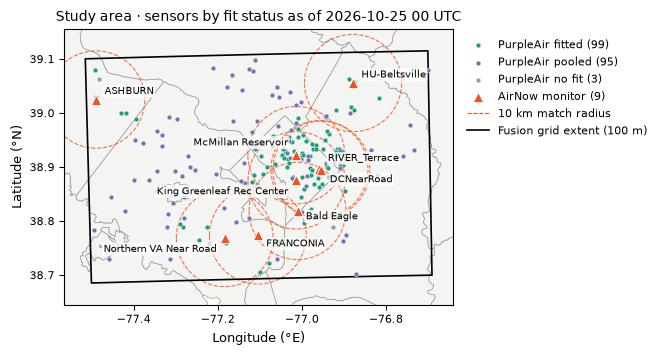

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 5.6), layout="constrained")
counties.plot(ax=ax, facecolor="#f4f4f2", edgecolor="#9a9a9a", linewidth=0.5, zorder=0)
circles.plot(ax=ax, facecolor="none", edgecolor="#f4511e", linewidth=0.8, linestyle="--",
             alpha=0.8, zorder=1)
grid_box.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=1.2, zorder=2)
for status, colour in STATUS_COLOURS.items():
    sub = sensors_g[sensors_g["status"] == status]
    if len(sub):
        ax.scatter(sub["longitude"], sub["latitude"], s=12, c=colour, edgecolor="white",
                   linewidth=0.3, zorder=3, label=f"PurpleAir {status} ({len(sub)})")
ax.scatter(monitors_g["longitude"], monitors_g["latitude"], linewidths=0.7,
           label=f"AirNow monitor ({len(monitors_g)})", **{**MONITOR_STYLE, "s": 55})
OFFSETS = {"RIVER_Terrace": (6, 6), "DCNearRoad": (6, -9), "McMillan Reservoir": (-6, 7),
           "King Greenleaf Rec Center": (-6, -10), "Bald Eagle": (6, -6),
           "FRANCONIA": (6, -8), "Northern VA Near Road": (-6, -10)}
for row in monitors_g.itertuples():
    dx, dy = OFFSETS.get(row.name, (6, 4))
    ax.annotate(row.name, (row.longitude, row.latitude), xytext=(dx, dy),
                textcoords="offset points", fontsize=7, ha="left" if dx > 0 else "right",
                zorder=5, bbox={"boxstyle": "round,pad=0.15", "fc": "white", "ec": "none",
                                "alpha": 0.75})
ax.plot([], [], color="#f4511e", linestyle="--", linewidth=0.8, label="10 km match radius")
ax.plot([], [], color="black", linewidth=1.2, label="Fusion grid extent (100 m)")
x0, y0, x1, y1 = grid_box.total_bounds
ax.set_xlim(x0 - 0.05, x1 + 0.05)
ax.set_ylim(y0 - 0.04, y1 + 0.04)
ax.set_aspect(1 / np.cos(np.deg2rad(38.9)))
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.set_title(f"Study area · sensors by fit status as of {AS_OF:%Y-%m-%d %H} UTC")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False)
finish(fig, "a_study_area",
       f"Study area: PurpleAir sensors coloured by calibration status for the fit as of "
       f"{AS_OF:%Y-%m-%dT%H} UTC, AirNow monitors (labelled) with 10 km matching radii, the "
       f"100 m fusion grid extent, and county boundaries (Census 2023 1:500k).")

### (b) One fitted sensor over one week

The example is the fitted sensor (as of 2026-10-25T00) with the highest r² among those within
1 km of their matched monitor; the week is the seven days ending at the fit's `as_of`. "Raw A/B mean" is the hourly mean of `(pm25_channel_a + pm25_channel_b) / 2` over
the hour's unflagged snapshots (the input the Barkjohn correction uses); "Barkjohn-corrected"
is the stored `pm25_corrected_mean`; "calibrated" is the stored `pm25_calibrated`, produced by
the daily fit in force each hour.

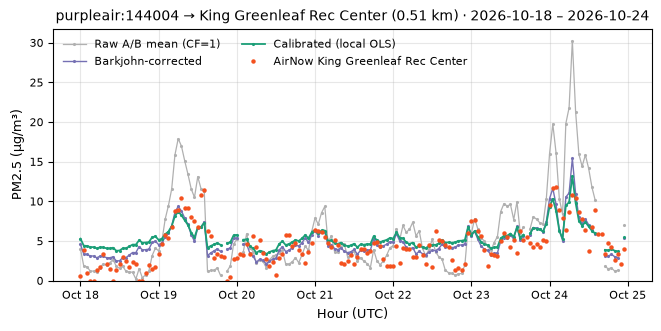

site_id                  purpleair:144004
as_of           2026-10-25 00:00:00+00:00
status                             fitted
ref_site_id           airnow:840110010053
distance_m                      511.59995
window_start    2026-09-25 00:00:00+00:00
window_end      2026-10-25 00:00:00+00:00
n_pairs                               639
slope                            0.763195
intercept                        1.427228
r2                               0.603228
rmse                             2.061508
d_km                               0.5116
Name: 4580, dtype: object


In [13]:
candidates = fitted_asof.assign(d_km=fitted_asof["distance_m"] / 1000)
candidates = candidates[candidates["d_km"] <= 1.0].sort_values("r2", ascending=False)
example = candidates.iloc[0]
EX, EX_REF = example["site_id"], example["ref_site_id"]
WEEK_END = AS_OF
WEEK_START = WEEK_END - timedelta(days=7)
week = pd.date_range(WEEK_START, WEEK_END, freq="h", inclusive="left")

pa_week = read_observations(ARCHIVE, Source.purpleair, WEEK_START.to_pydatetime(),
                            WEEK_END.to_pydatetime())
ex_obs = pa_week[(pa_week["site_id"] == EX) & pa_week["qc_flags"].map(len).eq(0)]
raw_ab = ((ex_obs["pm25_channel_a"] + ex_obs["pm25_channel_b"]) / 2).groupby(
    ex_obs["observed_at"].dt.floor("h")).mean()
cal_ex = calibrated[(calibrated["site_id"] == EX)].set_index("hour")
an_ex = an_fitspan[(an_fitspan["site_id"] == EX_REF) & an_fitspan["qc_flags"].map(len).eq(0)]
mon = an_ex.set_index("observed_at")["pm25_raw"]
ts = pd.DataFrame(index=week)
ts.index.name = "hour"
ts["raw_ab_mean"] = raw_ab
ts["barkjohn_corrected"] = cal_ex["pm25_corrected_mean"]
ts["calibrated"] = cal_ex["pm25_calibrated"]
ts["monitor"] = mon
ts["fit_as_of"] = cal_ex["fit_as_of"]
ts.to_csv(OUT / "fig_b_timeseries.csv")

fig, ax = plt.subplots(figsize=(6.5, 3.2), layout="constrained")
ax.plot(ts.index, ts["raw_ab_mean"], color="#b0b0b0", lw=0.9, label="Raw A/B mean (CF=1)",
        marker=".", ms=2.5)
ax.plot(ts.index, ts["barkjohn_corrected"], color="#7570b3", lw=1.0, label="Barkjohn-corrected",
        marker=".", ms=2.5)
ax.plot(ts.index, ts["calibrated"], color="#1b9e77", lw=1.3, label="Calibrated (local OLS)",
        marker=".", ms=2.5)
ax.plot(ts.index, ts["monitor"], color="#f4511e", lw=0, marker="o", ms=2.2,
        label=f"AirNow {names[EX_REF]}")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_xlabel("Hour (UTC)")
ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%b %d"))
ax.set_ylim(bottom=0)
ax.set_title(f"{EX} → {names[EX_REF]} ({example['d_km']:.2f} km) · "
             f"{WEEK_START:%Y-%m-%d} – {WEEK_END - timedelta(hours=1):%Y-%m-%d}")
ax.legend(ncols=2, frameon=False, loc="upper left")
ax.grid(alpha=0.3)
finish(fig, "b_timeseries",
       f"Hourly PM2.5 for fitted sensor {EX} and its matched monitor {names[EX_REF]} "
       f"({example['d_km']:.2f} km), {WEEK_START:%Y-%m-%d} to {WEEK_END:%Y-%m-%d}: raw A/B mean, "
       f"Barkjohn-corrected, locally calibrated, and the monitor's trusted hourly values.")
print(example)

### (c) That sensor's calibration scatter

The pairs are the fit's own (rebuilt with `calibration_pairs` for as_of 2026-10-25T00, 30-day
window); the line is the stored OLS fit.

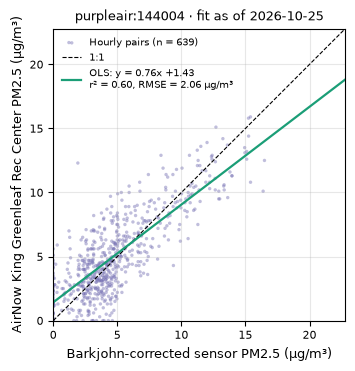

In [14]:
pairs = rebuilt[AS_OF].pairs[EX]
assert len(pairs) == example["n_pairs"]
pairs.to_csv(OUT / "fig_c_scatter_pairs.csv", index=False)
fig, ax = plt.subplots(figsize=(3.6, 3.6), layout="constrained")
ax.scatter(pairs["x"], pairs["y"], s=6, alpha=0.45, color="#7570b3", edgecolor="none",
           label=f"Hourly pairs (n = {len(pairs)})")
top = float(np.nanmax([pairs["x"].max(), pairs["y"].max()])) * 1.05
xs = np.array([0, top])
ax.plot(xs, xs, color="black", lw=0.8, ls="--", label="1:1")
ax.plot(xs, example["intercept"] + example["slope"] * xs, color="#1b9e77", lw=1.6,
        label=f"OLS: y = {example['slope']:.2f}x {example['intercept']:+.2f}\n"
              f"r² = {example['r2']:.2f}, RMSE = {example['rmse']:.2f} µg/m³")
ax.set_xlim(0, top)
ax.set_ylim(0, top)
ax.set_aspect("equal")
ax.set_xlabel("Barkjohn-corrected sensor PM2.5 (µg/m³)")
ax.set_ylabel(f"AirNow {names[EX_REF]} PM2.5 (µg/m³)")
ax.set_title(f"{EX} · fit as of {AS_OF:%Y-%m-%d}", fontsize=9)
ax.legend(frameon=False, loc="upper left", fontsize=7)
ax.grid(alpha=0.3)
finish(fig, "c_scatter",
       f"Calibration pairs for {EX} against {names[EX_REF]} in the fit window "
       f"[{AS_OF - window:%Y-%m-%d}, {AS_OF:%Y-%m-%d}): Barkjohn-corrected hourly mean vs monitor, "
       f"with the stored OLS line and the 1:1 line.")

### (d) QC flag rates

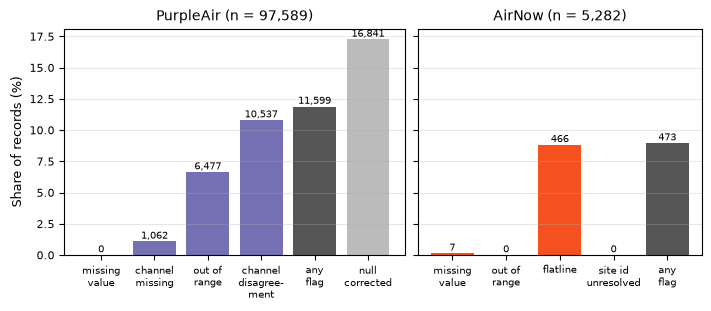

In [15]:
SHORT = {"missing_value": "missing\nvalue", "channel_missing": "channel\nmissing",
         "out_of_range": "out of\nrange", "channel_disagreement": "channel\ndisagree-\nment",
         "flatline": "flatline", "site_id_unresolved": "site id\nunresolved",
         "any_flag": "any\nflag", "null_pm25_corrected": "null\ncorrected"}
fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.0), sharey=True, layout="constrained",
                         width_ratios=[6, 5])
for ax, (source, colour) in zip(axes, [("purpleair", "#7570b3"), ("airnow", "#f4511e")]):
    sub = qc_flags[qc_flags["source"] == source]
    colours = [{"any_flag": "#555555", "null_pm25_corrected": "#bbbbbb"}.get(f, colour)
               for f in sub["flag"]]
    bars = ax.bar(sub["flag"].map(SHORT), sub["share"] * 100, color=colours)
    for b, n in zip(bars, sub["count"]):
        ax.annotate(f"{n:,}", (b.get_x() + b.get_width() / 2, b.get_height()),
                    xytext=(0, 2), textcoords="offset points", ha="center", fontsize=7)
    total = len(pa_obs) if source == "purpleair" else len(an_obs)
    ax.set_title(f"{'PurpleAir' if source == 'purpleair' else 'AirNow'} (n = {total:,})")
    ax.tick_params(axis="x", labelsize=7)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Share of records (%)")
finish(fig, "d_qc_rates",
       "QC flag rates by source: share of PurpleAir snapshots and AirNow hourly observations "
       "carrying each flag, any flag (dark grey), and, for PurpleAir, a null Barkjohn-corrected "
       "value (light grey); bar labels are counts.")

### (e) Match distance and fitted slopes

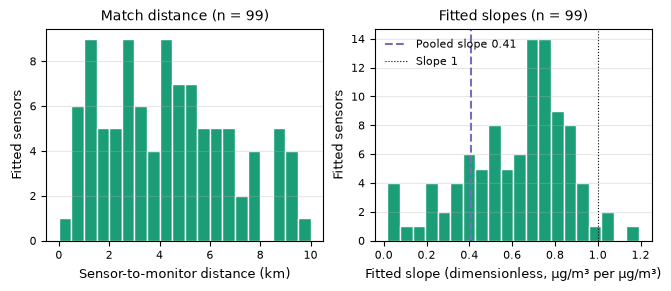

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(6.5, 2.8), layout="constrained")
axes[0].hist(fitted_asof["distance_m"] / 1000, bins=np.arange(0, 10.5, 0.5), color="#1b9e77",
             edgecolor="white")
axes[0].set_xlabel("Sensor-to-monitor distance (km)")
axes[0].set_ylabel("Fitted sensors")
axes[0].set_title(f"Match distance (n = {len(fitted_asof)})")
axes[1].hist(fitted_asof["slope"], bins=20, color="#1b9e77", edgecolor="white")
axes[1].axvline(pooled_row["slope"], color="#7570b3", lw=1.5, ls="--",
                label=f"Pooled slope {pooled_row['slope']:.2f}")
axes[1].axvline(1.0, color="black", lw=0.8, ls=":", label="Slope 1")
axes[1].set_xlabel("Fitted slope (dimensionless, µg/m³ per µg/m³)")
axes[1].set_ylabel("Fitted sensors")
axes[1].set_title(f"Fitted slopes (n = {len(fitted_asof)})")
axes[1].legend(frameon=False)
for ax in axes:
    ax.grid(axis="y", alpha=0.3)
fitted_asof[["site_id", "ref_site_id", "distance_m", "slope"]].to_csv(
    OUT / "fig_e_histograms.csv", index=False)
finish(fig, "e_histograms",
       f"Distributions for the {len(fitted_asof)} fitted sensors in the fit as of "
       f"{AS_OF:%Y-%m-%dT%H}: distance to the matched monitor and fitted OLS slope (pooled slope "
       f"and slope 1 marked).")

### (f) One hour's surface and standard deviation

The hour is chosen from the kriged hours whose variogram resolves spatial structure at the
network's sensor spacing — range ≥ 5 km and nugget ≤ half the sill — taking the one with the
highest mean trusted monitor value. (Hours whose fitted range is shorter than the typical
sensor spacing produce a nearly flat surface at the hour's mean with the SD at the sill
everywhere; the window's highest-monitor-mean hour, 2026-10-25T05, is one of them.) Both panels are drawn with the maps segment's
`render_surface` on its fixed scales (PM2.5 0–10 µg/m³, SD 0–3 µg/m³; arrows mark clipping);
sensors are the hour's kriging inputs (`hour_sensors`) and monitors the AirNow sites.

kriged hours 576; with range >= 5 km and nugget <= sill/2: 243
highest-monitor-mean kriged hour: 2026-10-25 05:00:00+00:00


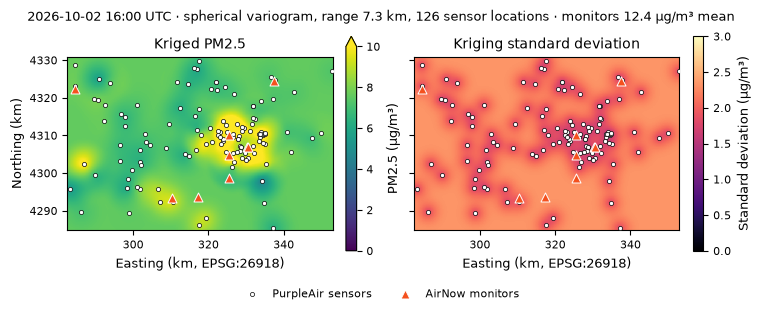

In [17]:
kriged = surface_fits[surface_fits["status"] == "kriged"]
structured = kriged[(kriged["range_m"] >= 5_000) & (kriged["nugget"] <= 0.5 * kriged["sill"])]
in_window_an = trusted_an.assign(hour=trusted_an["observed_at"].dt.floor("h"))
mean_by_hour = in_window_an.groupby("hour")["pm25_raw"].mean()
print(f"kriged hours {len(kriged)}; with range >= 5 km and nugget <= sill/2: {len(structured)}")
peak = mean_by_hour[mean_by_hour.index.isin(kriged["hour"])].idxmax()
print(f"highest-monitor-mean kriged hour: {peak}")
mean_by_hour = mean_by_hour[mean_by_hour.index.isin(structured["hour"])]
HOUR_F = mean_by_hour.idxmax()
fit_f = kriged.set_index("hour").loc[HOUR_F]
surface = read_surface(fit_f["surface_uri"])
grid_f = Grid(x_min=surface.transform.c, y_max=surface.transform.f,
              width=surface.pm25.shape[1], height=surface.pm25.shape[0],
              resolution_m=surface.transform.a)
hs = hour_sensors(calibrated, sites, HOUR_F.to_pydatetime())
mon_xy = monitor_sites.to_crs(PROJECTED_CRS)
sensors_xy = (hs["x"].to_numpy(float), hs["y"].to_numpy(float))
monitors_xy = (mon_xy.geometry.x.to_numpy(), mon_xy.geometry.y.to_numpy())

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.0), layout="constrained", sharey=True)
r1 = render_surface(axes[0], surface.pm25, grid_f, kind="pm25", sensors=sensors_xy,
                    monitors=monitors_xy)
add_colorbar(fig, r1.mappable, axes[0], kind="pm25", clipped=r1.clipped)
r2 = render_surface(axes[1], np.sqrt(surface.variance), grid_f, kind="sd", sensors=sensors_xy,
                    monitors=monitors_xy)
add_colorbar(fig, r2.mappable, axes[1], kind="sd", clipped=r2.clipped)
axes[0].set_title("Kriged PM2.5")
axes[1].set_title("Kriging standard deviation")
axes[1].set_ylabel("")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=2, frameon=False)
fig.suptitle(f"{HOUR_F:%Y-%m-%d %H}:00 UTC · {fit_f['variogram_model']} variogram, "
             f"range {fit_f['range_m'] / 1000:.1f} km, {int(fit_f['n_points'])} sensor locations · "
             f"monitors "
             f"{mean_by_hour[HOUR_F]:.1f} µg/m³ mean", fontsize=9)
pd.DataFrame([{
    "hour": HOUR_F, "surface_uri": fit_f["surface_uri"],
    "variogram_model": fit_f["variogram_model"],
    "sill": fit_f["sill"], "range_m": fit_f["range_m"], "nugget": fit_f["nugget"],
    "n_sensors": fit_f["n_sensors"], "n_points": fit_f["n_points"],
    "pm25_max": r1.max, "pm25_clipped_fraction": r1.clipped_fraction,
    "sd_max": r2.max, "sd_clipped_fraction": r2.clipped_fraction,
    "monitor_mean": mean_by_hour[HOUR_F],
}]).to_csv(OUT / "fig_f_surface.csv", index=False)
finish(fig, "f_surface",
       f"Fused surface for {HOUR_F:%Y-%m-%d %H}:00 UTC (the highest-monitor-mean hour among kriged "
       f"hours with variogram range >= 5 km and nugget <= sill/2): kriged PM2.5 and its "
       f"standard deviation on the 100 m grid, with the hour's "
       f"{len(hs)} kriging-input sensors (circles) and AirNow monitors (triangles).")

In [18]:
LETTERS = {"a_study_area": "(a)", "b_timeseries": "(b)", "c_scatter": "(c)",
           "d_qc_rates": "(d)", "e_histograms": "(e)", "f_surface": "(f)"}
figures_md = (
    "# Figures\n\nAll figures 300 dpi PNG; the data behind each is in the matching CSV.\n\n"
)
figures_md += "\n".join(
    f"- **{LETTERS[k]} `fig_{k}.png`** — {caption}" for k, caption in FIG.items()
) + "\n"
(OUT / "figures.md").write_text(figures_md)
print(figures_md)

# Figures

All figures 300 dpi PNG; the data behind each is in the matching CSV.

- **(a) `fig_a_study_area.png`** — Study area: PurpleAir sensors coloured by calibration status for the fit as of 2026-10-25T00 UTC, AirNow monitors (labelled) with 10 km matching radii, the 100 m fusion grid extent, and county boundaries (Census 2023 1:500k).
- **(b) `fig_b_timeseries.png`** — Hourly PM2.5 for fitted sensor purpleair:144004 and its matched monitor King Greenleaf Rec Center (0.51 km), 2026-10-18 to 2026-10-25: raw A/B mean, Barkjohn-corrected, locally calibrated, and the monitor's trusted hourly values.
- **(c) `fig_c_scatter.png`** — Calibration pairs for purpleair:144004 against King Greenleaf Rec Center in the fit window [2026-09-25, 2026-10-25): Barkjohn-corrected hourly mean vs monitor, with the stored OLS line and the 1:1 line.
- **(d) `fig_d_qc_rates.png`** — QC flag rates by source: share of PurpleAir snapshots and AirNow hourly observations carrying each flag, any flag (dark grey

## Summary

In [19]:
summary = {
    "pa_snapshots": len(pa_obs),
    "pa_sensors": pa_obs["site_id"].nunique(),
    "pa_snapshots_per_sensor_hour_median_iqr": (med, q1, q3),
    "pa_any_flag_share": pa_flags.set_index("flag").loc["any_flag", "share"],
    "pa_null_corrected_share": share(pa_null_corr, len(pa_obs)),
    "an_observations": len(an_obs),
    "an_sites": an_obs["site_id"].nunique(),
    "an_site_hours_expected_present": (expected, len(present)),
    "an_flatline": int(an_flags.set_index("flag").loc["flatline", "count"]),
    "sensor_hours": len(sensor_hourly),
    "sensor_hours_flagged_gt0": int((sensor_hourly["n_flagged"] > 0).sum()),
    "sensors_per_hour_median_min_max": (per_hour.median(), per_hour.min(), per_hour.max()),
    "fit_asof_fitted_pooled_uncal": (len(fitted_asof), len(pooled_asof),
                                     int((fit_asof["status"] == "uncalibrated").sum())),
    "fit_asof_within_10km": within_asof,
    "pooled_fit": (pooled_row["slope"], pooled_row["intercept"], pooled_row["r2"],
                   int(pooled_row["n_pairs"])),
    "example_sensor": (EX, names[EX_REF]),
    "surface_hour": HOUR_F,
}
for k, v in summary.items():
    print(f"{k:45s} {v}")

pa_snapshots                                  97589
pa_sensors                                    193
pa_snapshots_per_sensor_hour_median_iqr       (1.0, 1.0, 1.0)
pa_any_flag_share                             0.11885560872639335
pa_null_corrected_share                       0.17257067907243645
an_observations                               5282
an_sites                                      9
an_site_hours_expected_present                (5337, 5282)
an_flatline                                   466
sensor_hours                                  80616
sensor_hours_flagged_gt0                      0
sensors_per_hour_median_min_max               (np.float64(138.0), np.int64(0), np.int64(154))
fit_asof_fitted_pooled_uncal                  (99, 95, 0)
fit_asof_within_10km                          137
pooled_fit                                    (np.float64(0.4072673923460913), np.float64(2.800042334156303), np.float64(0.26944579182836026), 55797)
example_sensor                              